# 01_Data_Acquisition — Sources & Profiling

In [1]:
# Setup — vérification du répertoire de travail
from pathlib import Path
import sys

print("Répertoire courant :", Path.cwd())
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if not (ROOT / "config" / "config.yaml").exists():
    raise FileNotFoundError(
        f"config/config.yaml introuvable depuis {ROOT}. Lancer le notebook depuis la racine du dépôt "
        "ou depuis notebooks/.")
print("Racine du projet :", ROOT)

import yaml
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(ROOT / "src" / "data"))
from profile_report import connect, load_queries

cfg = yaml.safe_load((ROOT / "config" / "config.yaml").read_text(encoding="utf-8"))
FIG = ROOT / cfg["paths"]["figures"]
FIG.mkdir(parents=True, exist_ok=True)
con = connect()
Q = load_queries()
pd.set_option("display.max_rows", 100, "display.max_colwidth", 80)
print("Exports sélectionnés :", cfg["selected_exports"])
print("Requêtes chargées :", list(Q))

Répertoire courant : D:\Data analyst\Portfolio\Banque\bank-complaint-routing-nlp\notebooks
Racine du projet : D:\Data analyst\Portfolio\Banque\bank-complaint-routing-nlp
Exports sélectionnés : [15, 16, 17, 18, 19, 20, 21]
Requêtes chargées : ['Q1', 'Q2_global', 'Q2_by_export', 'Q2_by_product', 'Q3', 'Q4_product', 'Q4_product_subproduct', 'Q5_across_exports', 'Q5_within_export', 'Q6', 'Q6b', 'Q7', 'Q8', 'Q9']


## Sources sondées et fichiers locaux

Résultats des scripts `probe_sources.py` et `register_local.py`.

In [3]:
display(pd.read_csv(ROOT / "reports" / "source_probe.csv"))
display(pd.read_csv(ROOT / "reports" / "local_inventory.csv"))

,id,period,url,selected,http_status,content_length_bytes,content_length_mb,last_modified,content_type,error
0,1,December 2011 through April 2018,https://files.consumerfinance.gov/f/documents/CCDB_Export_1_December_2011_th...,False,200,134688697,128.4,"Mon, 14 Sep 2026 14:24:32 GMT",application/zip,NaN
1,2,May 2018 through April 2021,https://files.consumerfinance.gov/f/documents/CCDB_Export_2_May_2018_through...,False,200,164598156,157.0,"Mon, 14 Sep 2026 14:40:57 GMT",application/zip,NaN
2,3,May 2021 through October 2022,https://files.consumerfinance.gov/f/documents/CCDB_Export_3_May_2021_through...,False,200,128680448,122.7,"Mon, 14 Sep 2026 14:45:43 GMT",application/zip,NaN
3,4,November 2022 through August 2023,https://files.consumerfinance.gov/f/documents/CCDB_Export_4_November_2022_th...,False,200,115518181,110.2,"Mon, 14 Sep 2026 14:46:45 GMT",application/zip,NaN
4,5,September 2023 through March 2024,https://files.consumerfinance.gov/f/documents/CCDB_Export_5_September_2023_t...,False,200,100880669,96.2,"Mon, 14 Sep 2026 14:47:22 GMT",application/zip,NaN
5,6,April 2024 through July 2024,https://files.consumerfinance.gov/f/documents/CCDB_Export_6_April_2024_throu...,False,200,77142558,73.6,"Mon, 14 Sep 2026 14:47:50 GMT",application/zip,NaN
6,7,August 2024 through October 2024,https://files.consumerfinance.gov/f/documents/CCDB_Export_7_August_2024_thro...,False,200,71365591,68.1,"Mon, 14 Sep 2026 14:48:14 GMT",application/zip,NaN
7,8,November 2024 through December 2024,https://files.consumerfinance.gov/f/documents/CCDB_Export_8_November_2024_th...,False,200,52563546,50.1,"Mon, 14 Sep 2026 14:49:06 GMT",application/zip,NaN
8,9,January 2025 through February 2025,https://files.consumerfinance.gov/f/documents/CCDB_Export_9_January_2025_thr...,False,200,75475199,72.0,"Mon, 14 Sep 2026 14:50:18 GMT",application/zip,NaN
9,10,March 2025 through April 2025,https://files.consumerfinance.gov/f/documents/CCDB_Export_10_March_2025_thro...,False,200,68866998,65.7,"Mon, 14 Sep 2026 14:32:52 GMT",application/zip,NaN


,id,selected,file,present,size_mb,detected_format,n_header_fields,sha256
0,1,False,CCDB_Export_1_December_2011_through_April_2018.csv,True,520.8,csv,16,c5f287389af061205525b0aa492d64b546242d91661e3bcb0eba64ee34c9d87d
1,2,False,CCDB_Export_2_May_2018_through_April_2021.csv,True,746.6,csv,16,d80c844c72a86d8b2353037dd499d9b80d8f0d50f7b131565d057fb17e03acd7
2,3,False,CCDB_Export_3_May_2021_through_October_2022.csv,True,676.1,csv,16,8e3faea2ee94162d2053c404fbc65eeb03ee02db56ad91632241452165ac51c5
3,4,False,CCDB_Export_4_November_2022_through_August_2023.csv,True,695.1,csv,16,d75756baae955fb7019d561c1bb59e2880a4376ffdfafcd3609aef57bc851c98
4,5,False,CCDB_Export_5_September_2023_through_March_2024.csv,True,589.6,csv,16,7a8645f6f602762fcf8cdbf01005aaad9a5834debc9cab549ff94b6b128b1ab0
5,6,False,CCDB_Export_6_April_2024_through_July_2024.csv,True,493.2,csv,16,b5414ec55705da56307a5058ee928322099c1303d32d77a0061b132c418f88c1
6,7,False,CCDB_Export_7_August_2024_through_October_2024.csv,True,462.1,csv,16,3693607c2ace9c43098ab05e7541c33e2869ba776bac994eded1b30dad9889a4
7,8,False,CCDB_Export_8_November_2024_through_December_2024.csv,True,331.8,csv,16,2ef7d563bf6283a1282bcfba2d99d72f9bfa4a4617524682de72a9b3fa47bed0
8,9,False,CCDB_Export_9_January_2025_through_February_2025.csv,True,469.1,csv,16,b1a6a0d3b5f3a09723da8cce28a595342b586aa1629bbc8ed1e103cb295c8b06
9,10,False,CCDB_Export_10_March_2025_through_April_2025.csv,True,431.5,csv,16,2e5ffd7b3c1da2ec8772a5af179594cc72a524bd6ec64780163dd8516bb97a3c


## Q1 — Lignes et plage de dates par export

In [4]:
q1 = con.execute(Q["Q1"]).df()
display(q1)

,source_export_id,n_rows,min_date_received,max_date_received
0,15,1038383,2026-01-01,2026-02-28
1,16,614945,2026-03-01,2026-03-31
2,17,618293,2026-04-01,2026-04-30
3,18,619940,2026-05-01,2026-05-31
4,19,620794,2026-06-01,2026-06-30
5,20,672036,2026-07-01,2026-07-31
6,21,667140,2026-08-01,2026-08-31


## Q2 — Taux de narratifs non vides (global, par export, par produit)

In [5]:
q2_global = con.execute(Q["Q2_global"]).df()
display(q2_global)
q2_by_export = con.execute(Q["Q2_by_export"]).df()
display(q2_by_export)
q2_by_product = con.execute(Q["Q2_by_product"]).df()
display(q2_by_product)

,n_rows,n_with_narrative,pct_with_narrative
0,4851531,121394,2.5


,source_export_id,n_rows,n_with_narrative,pct_with_narrative
0,15,1038383,34351,3.31
1,16,614945,21640,3.52
2,17,618293,21052,3.40
3,18,619940,17528,2.83
4,19,620794,16820,2.71
5,20,672036,10002,1.49
6,21,667140,1,0.00


,product,n_rows,n_with_narrative,pct_with_narrative
0,Debt collection,220785,40205,18.21
1,Checking or savings account,60354,21335,35.35
2,Credit card,64866,20435,31.50
3,"Money transfer, virtual currency, or money service",25916,9807,37.84
4,Mortgage,23066,7772,33.69
5,Vehicle loan or lease,17022,5921,34.78
6,Credit reporting or other personal consumer reports,4405605,4945,0.11
7,"Payday loan, title loan, personal loan, or advance loan",12597,4356,34.58
8,Student loan,14228,4055,28.50
9,Prepaid card,4102,1462,35.64


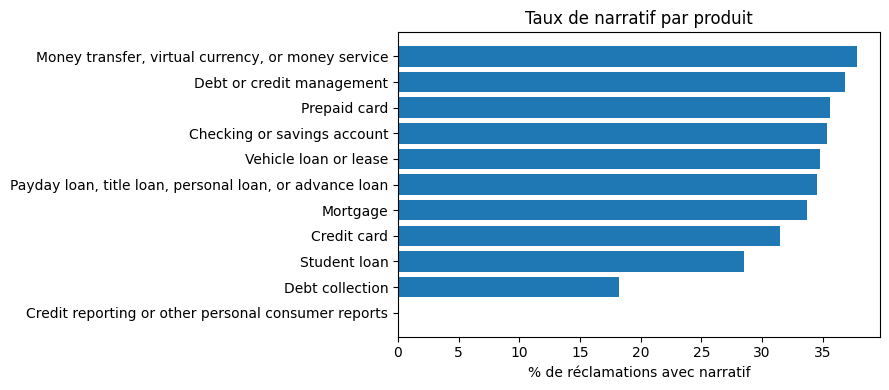

In [7]:
d = q2_by_product.sort_values("pct_with_narrative")
fig, ax = plt.subplots(figsize=(9, max(4, 0.35 * len(d))))
ax.barh(d["product"].astype(str), d["pct_with_narrative"])
ax.set_xlabel("% de réclamations avec narratif")
ax.set_title("Taux de narratif par produit")
fig.tight_layout()
fig.savefig(FIG / "narrative_rate_by_product.png", dpi=150)
plt.show()

## Q3 — Produit × mois : stabilité de la taxonomie

In [8]:
q3 = con.execute(Q["Q3"]).df()
display(q3)

,received_month,product,n_narratives
0,2026-01,Checking or savings account,3792
1,2026-01,Credit card,3788
2,2026-01,Credit reporting or other personal consumer reports,862
3,2026-01,Debt collection,7375
4,2026-01,Debt or credit management,212
5,2026-01,"Money transfer, virtual currency, or money service",1767
6,2026-01,Mortgage,1372
7,2026-01,"Payday loan, title loan, personal loan, or advance loan",800
8,2026-01,Prepaid card,322
9,2026-01,Student loan,763


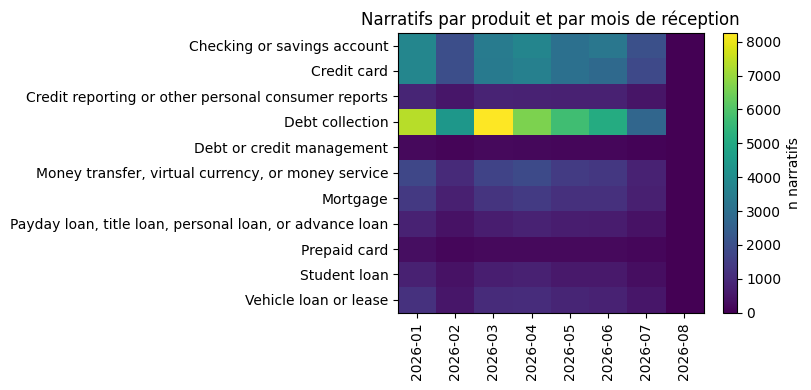

In [9]:
pivot = q3.pivot_table(index="product", columns="received_month", values="n_narratives", fill_value=0)
fig, ax = plt.subplots(figsize=(max(8, 0.6 * pivot.shape[1]), max(4, 0.35 * pivot.shape[0])))
im = ax.imshow(pivot.values, aspect="auto", cmap="viridis")
ax.set_xticks(range(pivot.shape[1]), pivot.columns, rotation=90)
ax.set_yticks(range(pivot.shape[0]), pivot.index)
ax.set_title("Narratifs par produit et par mois de réception")
fig.colorbar(im, ax=ax, label="n narratifs")
fig.tight_layout()
fig.savefig(FIG / "heatmap_product_month.png", dpi=150)
plt.show()

## Q4 — Valeurs distinctes de produit et sous-produit

In [10]:
q4_product = con.execute(Q["Q4_product"]).df()
display(q4_product)
q4_product_subproduct = con.execute(Q["Q4_product_subproduct"]).df()
display(q4_product_subproduct)

,product,n_narratives
0,Debt collection,40205
1,Checking or savings account,21335
2,Credit card,20435
3,"Money transfer, virtual currency, or money service",9807
4,Mortgage,7772
5,Vehicle loan or lease,5921
6,Credit reporting or other personal consumer reports,4945
7,"Payday loan, title loan, personal loan, or advance loan",4356
8,Student loan,4055
9,Prepaid card,1462


,product,sub_product,n_narratives
0,Checking or savings account,Checking account,17672
1,Checking or savings account,Other banking product or service,1921
2,Checking or savings account,Savings account,1482
3,Checking or savings account,CD (Certificate of Deposit),260
4,Credit card,General-purpose credit card or charge card,17709
5,Credit card,Store credit card,2726
6,Credit reporting or other personal consumer reports,Credit reporting,4915
7,Credit reporting or other personal consumer reports,Other personal consumer report,30
8,Debt collection,I do not know,18142
9,Debt collection,Credit card debt,6747


## Q5 — Doublons d'identifiant (entre exports, dans un export)

In [11]:
q5_across_exports = con.execute(Q["Q5_across_exports"]).df()
display(q5_across_exports)
q5_within_export = con.execute(Q["Q5_within_export"]).df()
display(q5_within_export)

,n_ids_in_multiple_exports
0,0


,source_export_id,n_duplicated_ids,n_rows_involved
0,15,0,0.0
1,16,0,0.0
2,17,0,0.0
3,18,0,0.0
4,19,0,0.0
5,20,0,0.0
6,21,0,0.0


## Q6 — Doublons exacts de texte (dont textes portant des produits différents)

In [12]:
q6 = con.execute(Q["Q6"]).df()
display(q6)
q6b = con.execute(Q["Q6b"]).df()
display(q6b)

,n_texts_duplicated,n_rows_involved
0,2014,13777.0


,n_texts_multi_product,n_rows_involved
0,43,245.0


## Q7 — Longueur des narratifs en mots

In [13]:
q7 = con.execute(Q["Q7"]).df()
display(q7)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,min,p5,p25,median,p75,p95,max
0,5,32.0,89.0,171.0,286.0,579.0,5347


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

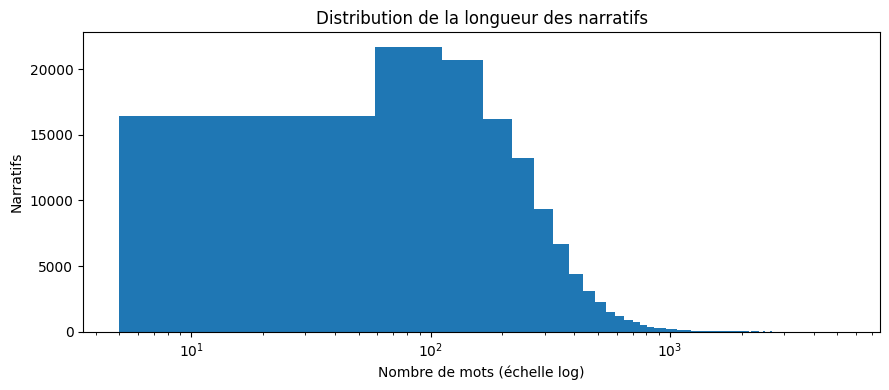

In [14]:
import json
ncol = json.loads((ROOT / cfg["paths"]["interim"] / "columns.json").read_text(encoding="utf-8"))["keys"]["narrative"]
words = con.execute(
    f"""SELECT len(string_split(trim(regexp_replace("{ncol}", '\\s+', ' ', 'g')), ' ')) AS n_words FROM narr_c"""
).df()["n_words"]
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(words, bins=100)
ax.set_xscale("log")
ax.set_xlabel("Nombre de mots (échelle log)")
ax.set_ylabel("Narratifs")
ax.set_title("Distribution de la longueur des narratifs")
fig.tight_layout()
fig.savefig(FIG / "narrative_length_hist.png", dpi=150)
plt.show()

## Q8 — Masques XXXX

In [15]:
q8 = con.execute(Q["Q8"]).df()
display(q8)

,pct_narratives_with_mask,avg_masks_per_narrative
0,79.19,10.59


## Q9 — Produit « credit reporting »

In [16]:
q9 = con.execute(Q["Q9"]).df()
display(q9)

,product,n_narratives,pct_of_narratives
0,Credit reporting or other personal consumer reports,4945,4.07


## Chiffres clés extraits (pour la conclusion)

In [17]:
g = q2_global.iloc[0]
print(f"Lignes totales            : {int(g.n_rows):,}")
print(f"Lignes avec narratif      : {int(g.n_with_narrative):,} ({g.pct_with_narrative} %)")
print(f"Mois observés             : {q3.received_month.min()} → {q3.received_month.max()}")
print(f"Produits distincts        : {q4_product['product'].nunique()}")
print(f"Id dans plusieurs exports : {int(q5_across_exports.iloc[0, 0]):,}")
print(f"Textes dupliqués          : {int(q6.n_texts_duplicated.iloc[0]):,}")
print(f"Médiane mots              : {q7['median'].iloc[0]}")
print(f"% narratifs avec masque   : {q8.pct_narratives_with_mask.iloc[0]}")

Lignes totales            : 4,851,531
Lignes avec narratif      : 121,394 (2.5 %)
Mois observés             : 2026-01 → 2026-08
Produits distincts        : 11
Id dans plusieurs exports : 0
Textes dupliqués          : 2,014
Médiane mots              : 171.0
% narratifs avec masque   : 79.19


## Constats factuels

Rédigé le 2026-10-05 à partir des sorties ci-dessus. Chiffres observés sur les exports 15 à 21 (réclamations reçues du 2026-01-01 au 2026-08-31), sans interprétation de modélisation :

- **Volume :** 4 851 531 réclamations, dont 121 394 avec narratif non vide (2,5 %).
- **Taux de narratif par export :** de 3,52 % (export 16) à 1,49 % (export 20) ; export 21 (août 2026) : 1 narratif sur 667 140 lignes.
- **Taux de narratif par produit :** de 37,84 % (*Money transfer, virtual currency, or money service*) à 0,11 % (*Credit reporting or other personal consumer reports*).
- **Taxonomie :** 11 produits, ensemble identique chaque mois de 2026-01 à 2026-07. Août 2026 exclu de la comparaison (1 narratif, sous le seuil de 1 717 = 10 % du volume mensuel médian de 17 174).
- **Fenêtre validée :** 2026-01 → 2026-07 (7 mois).
- **Doublons :** 0 identifiant dupliqué ; 2 014 textes identiques répartis sur 13 777 lignes, dont 43 textes (245 lignes) portant des produits différents.
- **Longueur des narratifs (mots) :** min 5, p5 32, p25 89, médiane 171, p75 286, p95 579, max 5 347.
- **Masques XXXX :** présents dans 79,19 % des narratifs, 10,59 par narratif en moyenne.
- **Credit reporting :** 4 945 narratifs (4,07 % des narratifs), exclus de la cible.

Rapport complet généré : `reports/phase1_profile.md`.